---
title: "Time-Independent Perturbation Theory — Level 2"
short_title: "08 Perturbation Theory"
numbering:
  heading_2: true
  equation: true
---

# Time-Independent Perturbation Theory

:::{seealso} Math for this topic
- [M1: Vectors and ODEs](../../level2-book/math/01-vectors-odes.ipynb)
- [M6: Linear algebra](../../level2-book/math/06-linear-algebra.ipynb)
- [Q-M3: Hilbert space and Dirac notation](../math/03-hilbert-space-dirac.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | — (a gap in Tipler & Mosca) | Not covered; start at Level 2 |
| **2** | **Griffiths QM, ch. 6** | **Non-degenerate and degenerate perturbation theory, fine structure, Zeeman and Stark effects** |
| 3 | Sakurai, ch. 5 | Systematic higher-order perturbation theory, Dalgarno–Lewis, Rayleigh–Schrödinger |

The new skill at this level: approximating energies of a slightly changed system as corrections built from the unperturbed solutions

Math for this topic: mechanics M1 (Taylor series), mechanics M6 (eigenvalues and matrices) and Q-M3 (Dirac notation).
:::

Workbook example ladder: the energy shift in a weakly perturbed well → the fine structure of hydrogen → the second-order Stark shift. Exercises have separate hint and answer dropdowns.

::::{admonition} Pre-test: can you skip this notebook?
:class: dropdown

Work these without looking at the notes. Each problem names the section it tests. If **every part** is right, skip ahead to [Q-M5: Asymptotics, WKB and Bessel functions](../math/05-asymptotics-wkb-bessel.ipynb), the math for the next chapter. If you miss a part, study just the section it names and try that problem again.

1. **The Idea**

   (a) In the infinite well $0 < x < a$, add $V_0$ over the left half only. Find the first-order shift of every level.

   (b) Why is the second-order correction to the ground state always negative?

2. **The Idea**: checking against an exact answer

   Add $\hat H' = \lambda x^2$ to a harmonic oscillator. Find the first-order shift of level $n$, and compare it with the exact answer expanded to first order in $\lambda$.

3. **Degenerate Perturbation Theory**

   Two degenerate states have perturbation matrix $\begin{pmatrix}0 & W\\ W & 0\end{pmatrix}$. Find the shifts and the "good" states. Why does the nondegenerate formula fail here?

4. **Degenerate Perturbation Theory**: the linear Stark effect in hydrogen

   (a) Why does hydrogen's ground state have no linear Stark effect, while $n = 2$ does?

   (b) Find the largest $n = 2$ shift, $3eEa$, in a field of $10^6$ V/m.

5. **Fine Structure of Hydrogen**

   Fine structure is of order $\alpha^2E_n$. Find $\alpha^2$. Which quantum numbers does the fine-structure energy depend on, and which $n = 2$ levels stay degenerate?

6. **The Zeeman Effect (weak field)**

   Find the splitting between $m_j = \pm\tfrac12$ of hydrogen's ground state ($g_J = 2$) in a 1.0 T field, in eV. Use $\mu_B = 5.79\times10^{-5}$ eV/T.

:::{dropdown} Answers
1. (a) $E_n^1 = \langle n|V_0|n\rangle_{\text{left half}} = V_0/2$ for every $n$, by the symmetry of $\sin^2$ about $a/2$.

   (b) Every term $|\langle m|H'|0\rangle|^2/(E_0 - E_m)$ has a negative denominator.

2. $E_n^1 = \lambda\langle x^2\rangle = \lambda\dfrac{\hbar}{2m\omega}(2n + 1)$. Exactly, $\omega' = \omega\sqrt{1 + 2\lambda/m\omega^2} \approx \omega(1 + \lambda/m\omega^2)$, which gives the same shift.

3. The shifts are $\pm W$, with good states $(|1\rangle \pm |2\rangle)/\sqrt2$. The nondegenerate formula divides by $E_1^0 - E_2^0 = 0$.

4. (a) The ground state is nondegenerate with definite parity, so $\langle z\rangle = 0$. At $n = 2$, $2s$ and $2p$ have opposite parity and the same energy, so the field mixes them at first order.

   (b) $3eEa \approx 1.6\times10^{-4}$ eV.

5. $\alpha^2 \approx 5.3\times10^{-5}$. It depends only on $n$ and $j$, so $2s_{1/2}$ and $2p_{1/2}$ stay degenerate (until the Lamb shift).

6. $g_J\mu_BB = 2\mu_B(1\ \text{T}) \approx 1.2\times10^{-4}$ eV.
:::
::::

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq
from scipy import special

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
hbar = 1.054572e-34    # J s
m_e = 9.10938e-31      # kg
eV = 1.602177e-19      # J
a0 = 5.29177e-11       # m (Bohr radius)
np.seterr(over="ignore", divide="ignore", invalid="ignore")   # plots hit inf at the edges; harmless here

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## The Idea

Exactly solvable problems are rare. Perturbation theory starts from one, $\hat H^0\psi_n^0 = E_n^0\psi_n^0$, and asks what a small extra term $\hat H'$ does. Write $\hat H = \hat H^0 + \lambda\hat H'$, expand $E_n$ and $\psi_n$ in powers of $\lambda$ (a bookkeeping parameter, set to 1 at the end), and match powers in $\hat H\psi_n = E_n\psi_n$:

$$
E_n = E_n^0 + E_n^1 + E_n^2 + \cdots
$$

**First order.** Take the inner product of the $\lambda^1$ equation with $\psi_n^0$; Hermiticity of $\hat H^0$ cancels the unknown first-order wave function, leaving

$$
E_n^1 = \langle\psi_n^0|\hat H'|\psi_n^0\rangle .
$$ (eq-first-order-energy)

The first-order shift is the perturbation averaged over the unperturbed state.

**First-order state and second-order energy.** Expanding $\psi_n^1$ in the unperturbed basis,

$$
\psi_n^1 = \sum_{m\ne n}\frac{\langle\psi_m^0|\hat H'|\psi_n^0\rangle}{E_n^0 - E_m^0}\psi_m^0,\qquad
E_n^2 = \sum_{m\ne n}\frac{|\langle\psi_m^0|\hat H'|\psi_n^0\rangle|^2}{E_n^0 - E_m^0} .
$$ (eq-second-order)

Two consequences of the second formula: the ground state's second-order shift is always negative (every denominator is negative), and nearby levels "repel" (a level above pushes $E_n$ down, one below pushes it up). The denominators also show where the method fails: when two unperturbed levels are equal.

::::{prf:example} Level 1–2 rung: a bump in the infinite well
:label: ex-well-bump

Raise the floor of the infinite well by $V_0$ over the middle half, $a/4 < x < 3a/4$. Find the first-order shifts of the ground and first excited states.

:::{dropdown} Solution
$E_n^1 = V_0\int_{a/4}^{3a/4}\frac2a\sin^2\frac{n\pi x}{a}dx = V_0\left[\frac12 + \frac{(-1)^{(n-1)/2}}{n\pi}\right]$ for odd $n$ and $V_0/2$ for even $n$ (the SymPy cell evaluates it). The ground state, which piles up in the middle, shifts by $(\tfrac12 + \tfrac1\pi)V_0 = 0.818V_0$; the $n = 2$ state, with a node at the center, by exactly $0.5V_0$.
:::
::::

In [2]:
x, a, V0 = sp.symbols("x a V_0", positive=True)
for n in [1, 2, 3, 4]:
    E1 = sp.integrate(V0 * 2 / a * sp.sin(n * sp.pi * x / a)**2, (x, a / 4, 3 * a / 4))
    display(Math(rf"E_{n}^1 = " + sp.latex(sp.simplify(E1)) + rf" \approx {float(E1.subs({V0: 1, a: 1})):.4f}\,V_0"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

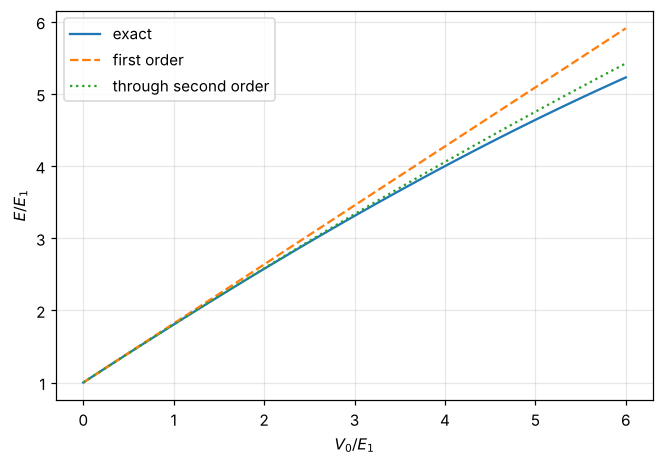

In [3]:
#| label: fig-pt-vs-exact
#| caption: "Ground-state energy of the well with a central bump, versus bump height V₀ (in units of E₁ = π²ħ²/2ma²). First order (dashed) is a straight line; adding the second-order sum (dotted) bends it down. Exact values (solid) from diagonalizing in the first 80 well states. First order is good to a few percent up to V₀ ≈ E₁."
N = 80
n = np.arange(1, N + 1)
xg = np.linspace(0, 1, 4001); dx = xg[1] - xg[0]
phi = np.sqrt(2) * np.sin(np.outer(n, np.pi * xg))
mask = (xg > 0.25) & (xg < 0.75)
Hp = (phi * mask) @ phi.T * dx                       # <m|H'|n> per unit V0
V0s = np.linspace(0, 6, 40)
exact = [np.linalg.eigvalsh(np.diag(n**2.0) + v * Hp)[0] for v in V0s]
first = 1 + V0s * Hp[0, 0]
second = first + V0s**2 * sum(Hp[0, m]**2 / (1 - (m + 1)**2) for m in range(1, N))
fig, ax = plt.subplots()
ax.plot(V0s, exact, label="exact"); ax.plot(V0s, first, "--", label="first order"); ax.plot(V0s, second, ":", label="through second order")
ax.set_xlabel("$V_0/E_1$"); ax.set_ylabel("$E/E_1$"); ax.legend(); plt.show()

## Degenerate Perturbation Theory

If $\psi_a^0$ and $\psi_b^0$ share the energy $E^0$, any combination $\alpha\psi_a^0 + \beta\psi_b^0$ is also an unperturbed eigenstate, and the second-order denominators blow up. The fix: the perturbation selects which combinations are the "good" starting states. Requiring the first-order equation to be solvable gives

$$
\begin{pmatrix}W_{aa} & W_{ab}\\ W_{ba} & W_{bb}\end{pmatrix}\begin{pmatrix}\alpha\\ \beta\end{pmatrix} = E^1\begin{pmatrix}\alpha\\ \beta\end{pmatrix},\qquad W_{ij} = \langle\psi_i^0|\hat H'|\psi_j^0\rangle .
$$ (eq-degenerate-pt)

**Diagonalize $\hat H'$ within the degenerate subspace.** Its eigenvalues are the first-order shifts and its eigenvectors are the good states. Shortcut: if some Hermitian operator $\hat A$ commutes with both $\hat H^0$ and $\hat H'$ and has different eigenvalues on the degenerate states, use its eigenstates; $\hat H'$ is already diagonal among them. For hydrogen this is how $\hat L_z$, $\hat J^2$ and $\hat J_z$ get used.

### The linear Stark effect in hydrogen

Put hydrogen in an electric field: $\hat H' = eEz$. The ground state shifts only at second order (it has no dipole: $\langle100|z|100\rangle = 0$ by parity). The $n = 2$ level is fourfold degenerate ($2s$ and three $2p$), and $\hat H'$ connects $|200\rangle$ and $|210\rangle$ only (it conserves $m$ and changes parity). The one nonzero matrix element is $\langle200|z|210\rangle = -3a$.

In [4]:
r, th = sp.symbols("r theta", positive=True)
R20 = 1 / sp.sqrt(2) * (1 - r / 2) * sp.exp(-r / 2)          # a = 1
R21 = 1 / sp.sqrt(24) * r * sp.exp(-r / 2)
Y00 = 1 / sp.sqrt(4 * sp.pi); Y10 = sp.sqrt(3 / (4 * sp.pi)) * sp.cos(th)
zme = sp.integrate(sp.integrate(R20 * Y00 * (r * sp.cos(th)) * R21 * Y10 * r**2 * sp.sin(th), (th, 0, sp.pi)) * 2 * sp.pi, (r, 0, sp.oo))
W = sp.Matrix([[0, zme], [zme, 0]])
display(Math(r"\langle 200|z|210\rangle = " + sp.latex(sp.simplify(zme)) + r"\,a,\qquad W/eE = " + sp.latex(W) + r",\quad E^1 = " + sp.latex(list(W.eigenvals().keys())) + r"\,eEa"))

<IPython.core.display.Math object>

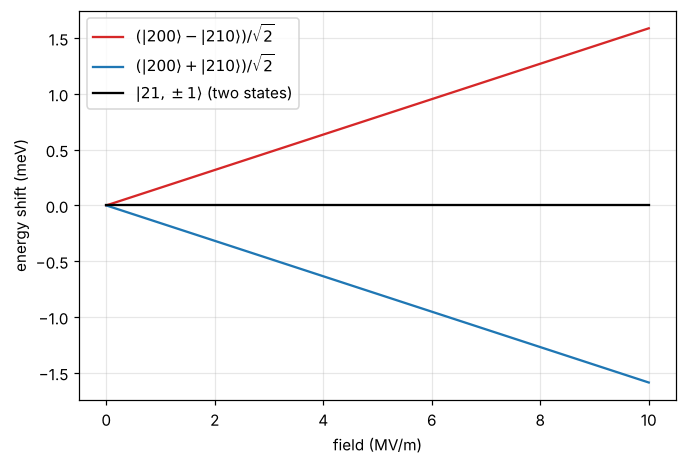

In [5]:
#| label: fig-stark-n2
#| caption: "First-order Stark splitting of hydrogen's n = 2 level. The combinations (|200⟩ ∓ |210⟩)/√2 shift by ±3eEa, linearly in the field; |211⟩ and |21,−1⟩ do not shift at first order. The field strengths shown are realistic for laboratory Stark spectroscopy."
Ef = np.linspace(0, 1e7, 50)                  # V/m
shift = 3 * 5.29177e-11 * Ef                  # eV, since e*E*a in eV = E[V/m]*a[m]
fig, ax = plt.subplots()
ax.plot(Ef / 1e6, 1e3 * shift, color="tab:red", label="$(|200\\rangle - |210\\rangle)/\\sqrt{2}$")
ax.plot(Ef / 1e6, -1e3 * shift, color="tab:blue", label="$(|200\\rangle + |210\\rangle)/\\sqrt{2}$")
ax.plot(Ef / 1e6, 0 * Ef, "k", label="$|21,\\pm1\\rangle$ (two states)")
ax.set_xlabel("field (MV/m)"); ax.set_ylabel("energy shift (meV)"); ax.legend(); plt.show()

## Fine Structure of Hydrogen

The Bohr energies come from a nonrelativistic Hamiltonian with no spin. The two leading corrections are both of relative size $\alpha^2\approx5\times10^{-5}$, where $\alpha = e^2/4\pi\epsilon_0\hbar c\approx1/137$ is the **fine-structure constant**:

- **relativistic kinetic energy:** $\sqrt{p^2c^2 + m^2c^4} - mc^2 = \frac{p^2}{2m} - \frac{p^4}{8m^3c^2} + \cdots$, so $\hat H'_r = -\hat p^4/8m^3c^2$;
- **spin–orbit coupling:** in the electron's rest frame the orbiting proton makes a magnetic field $\propto\vec L$, which acts on the spin's magnetic moment: $\hat H'_{so}\propto\frac{1}{r^3}\hat{\vec S}\cdot\hat{\vec L}$.

$\hat H'_{so}$ does not commute with $\hat L_z$ or $\hat S_z$ separately, but does commute with $\hat L^2$, $\hat S^2$, $\hat J^2$ and $\hat J_z$, so the good states are the coupled $|n\,\ell\,j\,m_j\rangle$ of topic 6. Adding the two first-order shifts gives a strikingly simple result:

$$
E^1_{\text{fs}} = -\frac{E_n^2}{2mc^2}\left(\frac{4n}{j + \tfrac12} - 3\right) .
$$ (eq-fine-structure)

It depends on $j$ but not on $\ell$: $2s_{1/2}$ and $2p_{1/2}$ stay degenerate. (Their tiny measured splitting, the Lamb shift, needs quantum electrodynamics.)

In [6]:
# Fine-structure shifts for n = 1..3 (in micro-eV), with alpha^2 m c^2 bookkeeping: E_n^2/(2mc^2) = (13.6 eV)^2 / (2 * 511 keV) / n^4
Ry, mc2 = 13.6057, 510998.95
lab = "spdf"
for n in [1, 2, 3]:
    En = -Ry / n**2
    parts = []
    for l in range(n):
        for j in sorted({l + 0.5, abs(l - 0.5)}):
            if j < 0: continue
            dE = -(En**2 / (2 * mc2)) * (4 * n / (j + 0.5) - 3)
            parts.append(rf"{n}{lab[l]}_{{{int(2 * j)}/2}}:\ {dE * 1e6:.1f}")
    display(Math(r"\text{shifts } (\mu\text{eV}):\ " + ",\\ ".join(parts)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

For $n = 2$ the $j = \tfrac12$ and $j = \tfrac32$ levels differ by about 45 μeV, which splits the H-α line into close components 0.016 nm apart.

## The Zeeman Effect (weak field)

In a magnetic field the electron's orbital and spin moments add $\hat H'_Z = \frac{e}{2m}(\hat{\vec L} + 2\hat{\vec S})\cdot\vec B$. When this is small compared with fine structure, $\hat J^2$ and $\hat J_z$ are still good, and the first-order shift is

$$
E_Z^1 = \mu_Bg_JB_{\text{ext}}m_j,\qquad g_J = 1 + \frac{j(j+1) - \ell(\ell+1) + \tfrac34}{2j(j+1)} ,
$$ (eq-weak-zeeman)

with $\mu_B = e\hbar/2m = 5.79\times10^{-5}$ eV/T the Bohr magneton and $g_J$ the **Landé g-factor**. Each $j$ level splits into $2j + 1$ equally spaced lines. In strong fields ($\mu_BB\gg$ fine structure) the good states become $|n\,\ell\,m_\ell\,m_s\rangle$ instead: the field decouples $\vec L$ and $\vec S$.

## Looking Ahead to Level 3

Sakurai carries the expansion to higher orders systematically, and shows how to sum some infinite sets of terms exactly (Dalgarno–Lewis). The second-order Stark shift of the hydrogen ground state is a classic: $E^2 = -\tfrac94(4\pi\epsilon_0)a^3E^2$, giving the atom's polarizability $\alpha_p = 4.5\,(4\pi\epsilon_0)a^3$, which the infinite sum over excited states produces exactly.

## Exercises

### Exercises

1. Add $\hat H' = \epsilon x$ to the harmonic oscillator. Find $E_n^1$ and $E_n^2$, and compare with the exact solution (complete the square).
2. Two states with $E_1^0 < E_2^0$ are coupled by $\hat H'$ with only an off-diagonal element $W$. Find the exact energies and check that second-order perturbation theory gives the first correction.
3. Find the first-order shift of the infinite well's $n$th level from a delta function $\hat H' = \alpha\delta(x - a/2)$. Which levels do not move, and why?
4. Find the fine-structure splitting between $2p_{3/2}$ and $2p_{1/2}$ in eV and as a frequency.
5. Find $g_J$ for the $2p_{1/2}$ and $2p_{3/2}$ levels and the Zeeman splitting between adjacent $m_j$ in a 1 T field.

:::{dropdown} Hints
1. $\langle n|x|n\rangle = 0$; $x$ connects $n$ only to $n\pm1$.
2. Diagonalize $\begin{pmatrix}E_1^0 & W\\ W & E_2^0\end{pmatrix}$ and expand for small $W$.
3. $E_n^1 = \alpha|\psi_n(a/2)|^2$.
4. Use {eq}`eq-fine-structure` with $n = 2$.
5. Use {eq}`eq-weak-zeeman` with $\ell = 1$.
:::

:::{dropdown} Answers
1. $E_n^1 = 0$, $E_n^2 = -\epsilon^2/2m\omega^2$ for every $n$. Exact: $x\to x + \epsilon/m\omega^2$ shifts every level by exactly $-\epsilon^2/2m\omega^2$, so second order is exact.
2. $E_\pm = \bar E\pm\sqrt{\Delta^2/4 + W^2}$; for small $W$, $E_1\approx E_1^0 - W^2/(E_2^0 - E_1^0)$, the second-order result.
3. $E_n^1 = (2\alpha/a)\sin^2(n\pi/2)$: $2\alpha/a$ for odd $n$, 0 for even $n$, which have a node at the center.
4. $\Delta E = 4.5\times10^{-5}$ eV, or 10.9 GHz.
5. $2p_{1/2}$: $g_J = 2/3$, splitting $3.9\times10^{-5}$ eV per tesla. $2p_{3/2}$: $g_J = 4/3$, splitting $7.7\times10^{-5}$ eV per tesla.
:::

## Summary

- First order: $E_n^1 = \langle n|\hat H'|n\rangle$. Second order: $\sum_{m\ne n}|\langle m|\hat H'|n\rangle|^2/(E_n^0 - E_m^0)$, always negative for the ground state.
- Degenerate levels: diagonalize $\hat H'$ in the degenerate subspace; symmetry operators that commute with both Hamiltonians pick the good states.
- Hydrogen $n = 2$ shows a linear Stark effect, $\pm3eEa$, because $2s$ and $2p$ are degenerate.
- Fine structure (relativity plus spin–orbit) is order $\alpha^2$ and depends only on $n$ and $j$; weak-field Zeeman splitting is $\mu_Bg_JBm_j$.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.